# Edit Flows that learn to delete — a walkthrough

This notebook explains, cell by cell, the discrete edit flow of this repository: a model that receives a
*source* sequence (a known target sequence with random letters inserted) and has to delete exactly the
inserted letters. It reads the results of a local training run and runs everything else live on the CPU.

| | |
|---|---|
| target $x_1$ | a known sequence over the letters `A`–`T` (ids 0–19, BOS = 20), 100–500 letters |
| source $x_0$ | the target with $K = \operatorname{round}(n_1(1/f-1))$ uniform letters inserted at uniform positions, $f \sim U(0.4, 0.9)$ |
| what the model must learn | which tokens are foreign to the sequence, and delete them — nothing else |
| how we measure it | the confusion matrix of the *delete* operation: precision, recall, F1 per length bucket, every epoch |

**Roadmap**

1. Data — letters, files, the placeholder dataset and why it has to be structured
2. Edit Flows in plain words
3. **Tooling: Lightning and Hydra, learned by doing** (§2b)
4. The extended coupling
5. The alignment is known (and agrees with Needleman–Wunsch)
6. The conditional path $z_t$, $x_t$
7. The model: a sequence encoder and the edit-flow head
8. The objective
9. Run analysis: curves per epoch, buckets, double descent?
10. What did the model learn? Rates per token
11. Watching the model edit, and the confusion matrix
12. Summary

**What runs where.** This notebook runs on a laptop CPU in roughly 10–15 minutes. It needs the run
`runs/local` (`python train.py experiment=deletion-local`, ~40 min on a CPU) or falls back to `runs/smoke`.
Large trainings go to a GPU cluster with the same code (`docs/CLUSTER.md`).

In [1]:
import os, sys, shutil, math, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "editflows").is_dir() else Path.cwd().parent
assert (ROOT / "editflows").is_dir(), "start the notebook inside the repository"
os.chdir(ROOT)                      # relative paths (data/, runs/) work like in train.py
sys.path.insert(0, str(ROOT))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

RUN = next((ROOT / "runs" / n for n in ("local", "smoke") if (ROOT / "runs" / n / "eval" / "deletion_metrics.csv").is_file()), None)
assert RUN is not None, "no run found: python train.py experiment=deletion-local"
print(f"run: {RUN.relative_to(ROOT)}   device: {device}")

from omegaconf import OmegaConf
from hydra.utils import instantiate
try:
    OmegaConf.register_new_resolver("eval", eval)   # train.py registers the same resolver
except ValueError:
    pass

from editflows import DataBatch, EditFlow, OptimalAligner, TokenWiseMixturePath, CubicKappaSchedule, LinearKappaSchedule
from editflows.editflows import rm_blanks
from editflows.coupling import ExtendedCoupling, KnownAligner, CoupledBatch
from editflows.metrics import Buckets, DeletionCounts
from editflows.deletion_task import to_device
from evaluate import load_model, render

cfg = OmegaConf.load(RUN / "config.yaml")
print(OmegaConf.to_yaml(cfg.task.coupling))

run: runs\smoke   device: cpu


C:\Users\laure\0envs\EditFlows_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


_target_: editflows.coupling.ExtendedCoupling
original_fraction:
- 0.4
- 0.9
n_letters: 20
bos_token: 20



## 1. Data

**Letters.** The alphabet is the string `ABCDEFGHIJKLMNOPQRST`; letter $i$ of it is token id $i$, and
`len(alphabet)` = 20 is the BOS token that starts every sequence. There is no padding token: batches are
*packed* — all tokens of a batch form one long vector `x` and `seq_lens` says where the sequences start
and end (`DataBatch`, from upstream). The model's vocabulary is therefore 21.

**Files.** `SequenceFileDataModule` reads one sequence per row from the first column of an `.xlsx` sheet,
a `.csv` or a text file, skips a header row, rejects letters outside the alphabet, caches the parsed file as
`.npz` next to it, and splits train / validation / test by a fixed permutation.

**The placeholder dataset.** The real target sequences come later. Until then
`scripts/make_synthetic_targets.py` writes sequences from an *order-2 Markov chain*: for every pair of
preceding letters only five next letters are possible. This matters: if the targets were independent uniform
letters, an inserted uniform letter would be statistically identical to an original one and nothing could
be learned. Deletions are learnable only if the targets have structure that insertions break.

file: data\synthetic\targets.xlsx   alphabet: ABCDEFGHIJKLMNOPQRST   BOS: 20   vocab: 21
train 18000  val 1000  test 1000
first validation sequence (with BOS): [20, 15, 0, 18, 16, 17, 8, 6, 14, 2, 4, 7] ...
as letters: PASQRIGOCEHKCJIHFKPGDSHBCGLECIBAONEGAPJLKQJFGCASQRINGMBIGOHJ ...


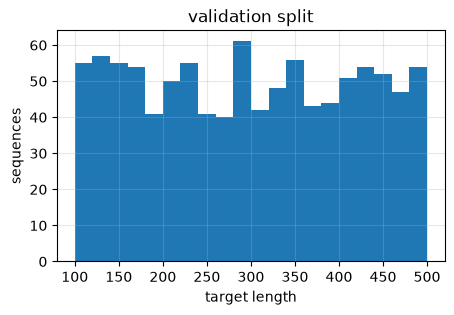

In [2]:
dm = instantiate(cfg.data, seed_sequence=np.random.SeedSequence(0))
dm.prepare_data(); dm.setup("fit"); dm.setup("test")
print(f"file: {dm.path}   alphabet: {dm.alphabet}   BOS: {dm.bos_token}   vocab: {dm.vocab_size}")
print(f"train {len(dm.train_data)}  val {len(dm.val_data)}  test {len(dm.test_data)}")

seq = dm.val_data[0]
print("first validation sequence (with BOS):", seq[:12].tolist(), "...")
print("as letters:", dm.decode(seq.tolist())[:60], "...")

lengths = np.diff(dm.val_data.offsets)[dm.val_data.indices]
plt.figure(figsize=(5, 3)); plt.hist(lengths, bins=20); plt.xlabel("target length"); plt.ylabel("sequences"); plt.title("validation split"); plt.show()

In [3]:
# How structured is the data? Count the distinct next letters after each pair of letters.
tokens = dm.train_data.tokens.astype(np.int64)
offsets = dm.train_data.offsets
nxt = {}
for i in dm.train_data.indices[:2000]:
    s = tokens[offsets[i]:offsets[i + 1]]
    for a, b, c in zip(s[:-2], s[1:-1], s[2:]):
        nxt.setdefault((a, b), set()).add(c)
sizes = np.array([len(v) for v in nxt.values()])
print(f"contexts seen: {len(nxt)}   distinct next letters per context: mean {sizes.mean():.2f}, max {sizes.max()} (uniform data would approach 20)")

contexts seen: 400   distinct next letters per context: mean 4.97, max 5 (uniform data would approach 20)


## 2. Edit Flows in plain words

An edit flow (Havasi et al., 2025) generates a sequence by applying *edit operations* to a starting
sequence over a time $t \in [0, 1]$: at every position it can **insert** a token after it, **substitute** the
token, or **delete** it. Each operation has a *rate* $\lambda$ — how often per unit of time it happens — and
for insertions and substitutions a distribution $Q$ over which token to use. A neural network looks at the
current sequence $x_t$ and the time $t$ and outputs all rates and $Q$s at once (`LogRate`: three log-rates
per token and $2 \times V$ logits).

Training needs pairs $(x_0, x_1)$ from a *coupling* and an *alignment* of the two sequences in an augmented
space: both are written with blanks $\epsilon$ so that they have the same length and position $i$ of $z_0$
corresponds to position $i$ of $z_1$ (deletion = token in $z_0$, blank in $z_1$; insertion = the other way
round; substitution = two different tokens). A *probability path* then interpolates: at time $t$ every
position shows the $z_1$ token with probability $\kappa(t)$ and the $z_0$ token otherwise (token-wise mixture
path, $\kappa(t) = t^3$ here). The loss (a Bregman divergence) rewards the model for putting rate on exactly the
edits that are still needed to get from $x_t$ to $x_1$, in proportion to $\dot\kappa / (1 - \kappa)$, and
penalises total rate. Sampling runs an Euler scheme from $x_0$: at every step every operation fires with
probability $h \lambda$.

**Here**, the coupling only ever requires deletions, the alignment is known, and the question is purely
whether the model recognises the foreign tokens.

## 2b. Tooling — Lightning and Hydra, learned by doing

The training code is organised with two libraries you will meet in every config file and in `train.py`.

### Hydra: configuration by composition

`config/` is a tree of YAML files. `train.yaml` is the root; its `defaults` list picks one file from each
*config group* (`data`, `task`, `logging`, `experiment`, ...) and `task/deletion.yaml` in turn picks
`model`, `coupling`, `aligner`, ... from the sub-groups. The result is one nested configuration object; every
leaf can be overridden on the command line (`task.optimizer.lr=1e-4`), a group can be swapped
(`task/model=cpu`), and *experiment* files (`# @package _global_`) are presets that override many keys at
once. Keys that do not exist yet need a `+` (`+trainer.limit_train_batches=2`).

Two things to know:
* `${a.b}` interpolates another key; `${eval:'...'}` evaluates arithmetic (`train.py` registers that resolver).
* A node with `_target_: some.module.Class` is turned into that object by `hydra.utils.instantiate`, nested
  nodes first. That is how `config/task/model/encoder-head.yaml` becomes `EncoderWithEditHead(encoder=LlamaEncoder(...))`.

In [4]:
def tree(path, prefix="", depth=0):
    entries = sorted(p for p in path.iterdir() if not p.name.startswith("."))
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        print(prefix + ("└── " if last else "├── ") + p.name)
        if p.is_dir():
            tree(p, prefix + ("    " if last else "│   "), depth + 1)

tree(ROOT / "config")

├── data
│   ├── sequences.yaml
│   └── text8.yaml
├── experiment
│   ├── default.yaml
│   ├── deletion-base.yaml
│   ├── deletion-local.yaml
│   ├── deletion-smoke.yaml
│   └── text8-180M.yaml
├── hydra
│   ├── default.yaml
│   └── launcher
│       └── slurm.yaml
├── logging
│   ├── csv+wandb.yaml
│   ├── csv.yaml
│   └── wandb.yaml
├── task
│   ├── aligner
│   │   ├── known.yaml
│   │   ├── optimal.yaml
│   │   └── shift.yaml
│   ├── coupling
│   │   ├── extended.yaml
│   │   └── independent.yaml
│   ├── deletion.yaml
│   ├── ema
│   │   └── ema.yaml
│   ├── lr_scheduler
│   │   ├── cosine.yaml
│   │   └── warmup.yaml
│   ├── model
│   │   ├── cpu.yaml
│   │   ├── encoder-head.yaml
│   │   └── llama2.yaml
│   ├── noise
│   │   ├── eqlen-uniform.yaml
│   │   └── none.yaml
│   ├── optimizer
│   │   ├── adam.yaml
│   │   └── adamw.yaml
│   ├── path
│   │   ├── kappa
│   │   │   ├── cubic.yaml
│   │   │   └── linear.yaml
│   │   └── token-wise.yaml
│   └── pretraining.yaml
└── train.yaml

In [5]:
from hydra import initialize_config_dir, compose
from hydra.core.global_hydra import GlobalHydra

def compose_config(*overrides):
    GlobalHydra.instance().clear()
    with initialize_config_dir(config_dir=str(ROOT / "config"), version_base=None):
        config = compose(config_name="train", overrides=list(overrides))
    OmegaConf.resolve(config)
    return config

smoke = compose_config("experiment=deletion-smoke")
print("model node of experiment=deletion-smoke:\n")
print(OmegaConf.to_yaml(smoke.task.model))

model_small = instantiate(smoke.task.model)
model_wide = instantiate(compose_config("experiment=deletion-smoke", "task.model.encoder.hidden_size=64").task.model)
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"parameters: hidden 32 -> {count(model_small):,}   hidden 64 -> {count(model_wide):,}")

model node of experiment=deletion-smoke:

_target_: editflows.edit_head.EncoderWithEditHead
vocab_size: 21
max_log_lambda: 10.0
encoder:
  _target_: editflows.encoder.LlamaEncoder
  vocab_size: 21
  hidden_size: 32
  num_hidden_layers: 2
  num_attention_heads: 2
  max_seq_len: 2048



parameters: hidden 32 -> 80,781   hidden 64 -> 210,669


### Lightning: the training loop as hooks

PyTorch Lightning separates *what* is computed from *how* the loop runs. Our `LightningModule` is
`DeletionTask`, which inherits upstream's `Pretraining`:

| hook | what it does here |
|---|---|
| `configure_model` | instantiates the model, the EMA copy, the coupling, the aligner and the path from their config nodes and hands `create_aligned_pair` to the datamodule (it runs in the data workers) |
| `training_step` | one batch $(x_0, x_1, z_0, z_1)$ → Bregman divergence → `self.log("train/loss")` |
| `validation_step` | the same loss on validation batches, plus the ranking proxy at $t = 0$ |
| `on_validation_epoch_end` | samples from a fixed subset of validation sources with provenance, all-reduces the integer counts across GPUs, logs `val/del_f1` & co. and writes `eval/deletion_metrics.csv` |
| `configure_optimizers` | AdamW + warm-up / cosine schedule (fills in the number of steps for epoch-based training) |

The `LightningDataModule` (`SequenceFileDataModule`) owns the data: `prepare_data` parses and caches the
file, `setup` splits it, `train_dataloader` / `val_dataloader` build the loaders with their samplers.

The `Trainer` runs the loop: epochs, validation after each epoch (`check_val_every_n_epoch`), gradient
clipping, mixed precision, and on a cluster distributed data parallel (`devices=N`) — without changes to the
module. *Callbacks* add behaviour: two `ModelCheckpoint`s (best `val/del_f1` + `last.ckpt`; `periodic.ckpt`
every 30 minutes), the learning-rate monitor, the progress bar, and upstream's `ConfigInCheckpoint` which
stores the configuration inside every checkpoint (that is what `evaluate.py` and this notebook rebuild the
model from). *Loggers* receive everything passed to `self.log`: the `CSVLogger` writes
`runs/<name>/logs/version_N/metrics.csv`.

`train.py` wires it all: compose the config → create the run directory → instantiate datamodule and task →
`Trainer(**config.trainer, callbacks=..., logger=...)` → `trainer.fit(task, datamodule, ckpt_path=<newest checkpoint>)`.

Let us run that loop for ten batches right here.

In [6]:
from lightning.pytorch import Trainer
from lightning.pytorch.loggers import CSVLogger

demo_dir = ROOT / "runs" / "nb-demo"
shutil.rmtree(demo_dir, ignore_errors=True)
demo = compose_config("experiment=deletion-smoke", "name=nb-demo", "task.eval.n_sample_seqs=8", "task.eval.sample_steps=10")

demo_dm = instantiate(demo.data, seed_sequence=np.random.SeedSequence(1))
demo_task = instantiate(demo.task, seed_sequence=np.random.SeedSequence(2))
trainer = Trainer(
    max_epochs=1, accelerator="cpu", devices=1, limit_train_batches=10, limit_val_batches=2, num_sanity_val_steps=0,
    log_every_n_steps=1, logger=CSVLogger(save_dir=demo_dir, name="logs"), default_root_dir=str(demo_dir),
    enable_checkpointing=False, enable_progress_bar=False, enable_model_summary=False,
)
trainer.fit(demo_task, datamodule=demo_dm)

print("\nwhat the run wrote:")
for p in sorted(demo_dir.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(demo_dir))
metrics = pd.read_csv(demo_dir / "logs" / "version_0" / "metrics.csv")
metrics.tail(3).T

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Loading `train_dataloader` to estimate number of stepping batches.


C:\Users\laure\0envs\EditFlows_env\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\laure\0envs\EditFlows_env\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
C:\Users\laure\0envs\EditFlows_env\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
W1106 16:55:39.408000 20212 Lib\site-packages\torch\fx\_symbolic_trace.py:56] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Pleas

C:\Users\laure\0envs\EditFlows_env\Lib\site-packages\torch\nested\__init__.py:118: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  return torch._nested_tensor_from_tensor_list(ts, dtype, None, device, None)


`Trainer.fit` stopped: `max_epochs=1` reached.



what the run wrote:
   eval\deletion_metrics.csv
   eval\val_epoch_0000.json
   logs\version_0\metrics.csv


,8,9,10
epoch,0.000000,0.000000,0.000000
step,8.000000,9.000000,9.000000
train/loss,716.982788,1021.773987,NaN
val/del_chance,NaN,NaN,0.472679
val/del_f1,NaN,NaN,0.199194
val/del_precision,NaN,NaN,0.471404
val/del_recall,NaN,NaN,0.126277
val/exact_match,NaN,NaN,0.000000
val/ins_per_seq,NaN,NaN,89.250000
val/len100-200/frac0.4-0.55/del_f1,NaN,NaN,0.225490


The same objects run on a cluster with `python train.py experiment=deletion-base name=<run> gpus=4`:
Lightning starts one process per GPU, the datamodule's `DistributedSampler` splits the data, the loss is
averaged across processes and `DeletionTask` all-reduces its counts. The run directory, the CSV files and
the checkpoints look exactly like the ones above.

### 🧑‍💻 Exercise 1


Compose the configuration with a *different* experiment and override, e.g. `experiment=deletion-local` and
`task.coupling.original_fraction=[0.5,0.5]`, and print the coupling node. Then add one more logged value to
the demo: subclass `DeletionTask`, override `training_step` to also `self.log("train/batch_tokens", ...)`
(the number of tokens in `batch[0].x`) and run the ten-batch training again — the new column appears in
`metrics.csv`.

In [7]:
# 🧑‍💻 Exercise 1 — your code here

## 3. The extended coupling

For a target of $n_1$ letters, `ExtendedCoupling` draws the *original fraction* $f \sim U(f_\min, f_\max)$,
inserts $K = \operatorname{round}(n_1 (1/f - 1))$ uniform letters at uniform *gaps* (before letter 0, between
letters, after the last letter; several insertions may share a gap) and remembers which source tokens are
inserted (`CoupledBatch.inserted`). The BOS token always stays first. The source batch is $n_1/f$ letters long
on average, so $f$ is literally "how much of the source is original".

The share of inserted tokens, $1 - f$, is also the **chance level** of deletion precision: deleting source
tokens at random hits an insertion with that probability. Every curve in this notebook shows it.

In [8]:
x_1 = DataBatch.from_sequences([dm.val_data[i] for i in range(4)])
coupling = ExtendedCoupling(original_fraction=(0.5, 0.5), n_letters=dm.n_letters, bos_token=dm.bos_token)
g = torch.Generator().manual_seed(0)
x_0, _ = coupling.couple(None, x_1, generator=g)

def show_pair(x_0, x_1, i, width=90):
    src = torch.split(x_0.x, list(x_0.seq_lens))[i][1:]
    ins = torch.split(x_0.inserted, list(x_0.seq_lens))[i][1:]
    tgt = x_1.split_sequences()[i][1:]
    source = "".join(c.lower() if k else c for c, k in zip(dm.decode(src.tolist()), ins.tolist()))
    ops = "".join("D" if k else "=" for k in ins.tolist())
    print(f"target ({len(tgt)}): {dm.decode(tgt.tolist())[:width]}")
    print(f"source ({len(src)}): {source[:width]}   (inserted letters in lower case)")
    print(f"edits        : {ops[:width]}   (D = delete, = keep)")

show_pair(x_0, x_1, 0)

target (220): PASQRIGOCEHKCJIHFKPGDSHBCGLECIBAONEGAPJLKQJFGCASQRINGMBIGOHJTPTBODOQEQRSTOKTEMPPCOHJDCCQNE
source (440): PiapAbSdaQRsIbGbOCbhEHmKCJmmInHngriFaKfPkGDnfSpHnBqmCmGLECpIpBAjONEGondArPJdiLahKfQsJFGmoC   (inserted letters in lower case)
edits        : =DDD=D=DD==D=D=D==DD==D===DD=D=DDDD=D=D=D==DD=D=D=DD=D====D=D==D====DDD=D==DD=DD=D=D===DD=   (D = delete, = keep)


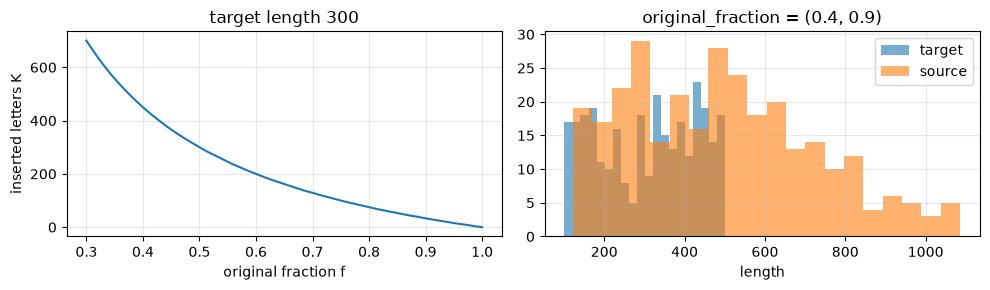

share of inserted tokens over the 300 sources (= chance precision): 0.377


In [9]:
# K as a function of f for a 300-letter target, and the source lengths of the validation split under the run's coupling
f = np.linspace(0.3, 1.0, 50)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.plot(f, np.round(300 * (1 / f - 1))); plt.xlabel("original fraction f"); plt.ylabel("inserted letters K"); plt.title("target length 300")
run_coupling = instantiate(cfg.task.coupling)
x_1_val = DataBatch.from_sequences([dm.val_data[i] for i in range(300)])
x_0_val, _ = run_coupling.couple(None, x_1_val, generator=torch.Generator().manual_seed(1))
plt.subplot(1, 2, 2); plt.hist(np.array(x_1_val.seq_lens) - 1, bins=20, alpha=0.6, label="target"); plt.hist(np.array(x_0_val.seq_lens) - 1, bins=20, alpha=0.6, label="source"); plt.legend(); plt.xlabel("length"); plt.title(f"original_fraction = {tuple(cfg.task.coupling.original_fraction)}")
plt.tight_layout(); plt.show()
print(f"share of inserted tokens over the 300 sources (= chance precision): {x_0_val.inserted.float().mean():.3f}")

### 🧑‍💻 Exercise 2


Change `original_fraction` to `(0.2, 0.2)` and to `(0.95, 0.95)` and look at a pair in each case. Which
of the two is harder for the model — fewer originals to identify, or fewer insertions to find? Think about
precision *and* recall separately before you look at §9.

In [10]:
# 🧑‍💻 Exercise 2 — your code here

## 4. The alignment is known

Upstream aligns $x_0$ and $x_1$ with Needleman–Wunsch (`OptimalAligner`) in the data workers. For the
extended coupling that search is unnecessary: the inserted mask *is* the alignment. `KnownAligner` writes
$z_0 = x_0$ and $z_1 = x_0$ with the inserted positions blanked, so that `rm_blanks(z_1) == x_1`. The test
suite checks on random pairs that Needleman–Wunsch finds the same solution — $K$ deletions, no insertions,
no substitutions (a substitution would cost a match and one extra edit, so it can never be optimal here).

In [11]:
short = DataBatch.from_sequences([torch.tensor([dm.bos_token] + [dm.alphabet.index(c) for c in "ABCDEFGH"])])
short_0, _ = ExtendedCoupling(original_fraction=(0.6, 0.6), n_letters=20, bos_token=dm.bos_token).couple(None, short, generator=torch.Generator().manual_seed(3))
z_0, z_1 = KnownAligner().align(short_0, short)
letters = lambda row: " ".join("·" if t < 0 else ("^" if t == dm.bos_token else dm.alphabet[t]) for t in row.tolist())
print("z_0:", letters(z_0[0]))
print("z_1:", letters(z_1[0]), "   (· = blank)")
print("rm_blanks(z_1) == x_1:", torch.equal(rm_blanks(z_1).x, short.x))

nw_0, nw_1 = OptimalAligner().align(short_0, short)
ops = lambda a, b: dict(deletions=int(((a >= 0) & (b < 0)).sum()), insertions=int(((a < 0) & (b >= 0)).sum()), substitutions=int(((a >= 0) & (b >= 0) & (a != b)).sum()))
print("known alignment     :", ops(z_0, z_1))
print("Needleman-Wunsch    :", ops(nw_0, nw_1))

z_0: ^ A A F B C B T D E O F G H
z_1: ^ A · · B C · · D E · F G H    (· = blank)
rm_blanks(z_1) == x_1: True


known alignment     : {'deletions': 5, 'insertions': 0, 'substitutions': 0}
Needleman-Wunsch    : {'deletions': 5, 'insertions': 0, 'substitutions': 0}


## 5. The conditional path

At time $t$ each aligned position independently shows its $z_1$ value with probability $\kappa(t)$ and its $z_0$
value otherwise; $x_t = \operatorname{rmblanks}(z_t)$. With $\kappa(t) = t^3$ (cubic schedule) almost nothing
happens early and most deletions happen late; the loss weight of a still-needed edit is
$\dot\kappa/(1-\kappa) = 3t^2/(1-t^3)$ — this is also the *rate* an ideal model assigns to every inserted
token that is still present, and 0 to every original token. Note that it is tiny near $t = 0$: a per-token
"delete or not" decision read off the raw rate would be meaningless there, which is why the ranking
proxy of §9 compares rates *within* a sequence instead of thresholding them.

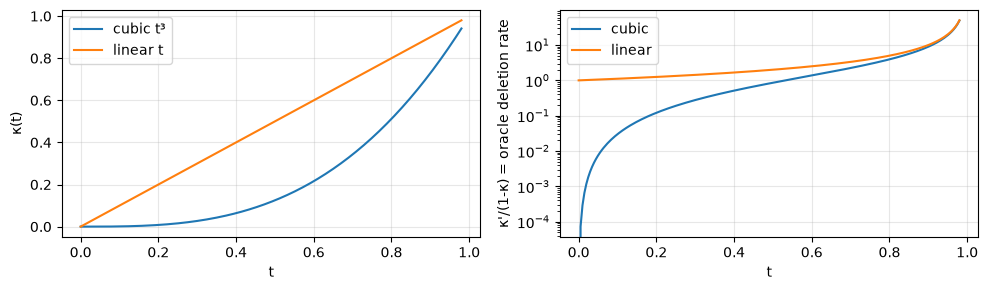

1119 insertions in the 4 sources;  insertions still present in x_t:
  t = 0.00: 1119   expected (1-κ)K = 1119.0
  t = 0.50:  961   expected (1-κ)K =  979.1
  t = 0.80:  548   expected (1-κ)K =  546.1
  t = 0.95:  151   expected (1-κ)K =  159.6


In [12]:
t = torch.linspace(0, 0.98, 200)
cubic, linear = CubicKappaSchedule(), LinearKappaSchedule()
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.plot(t, cubic(t), label="cubic t³"); plt.plot(t, linear(t), label="linear t"); plt.xlabel("t"); plt.ylabel("κ(t)"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(t, cubic.loss_coefficient(t), label="cubic"); plt.plot(t, linear.loss_coefficient(t), label="linear"); plt.yscale("log"); plt.xlabel("t"); plt.ylabel("κ'/(1-κ) = oracle deletion rate"); plt.legend()
plt.tight_layout(); plt.show()

path = TokenWiseMixturePath(cubic)
z_0, z_1 = KnownAligner().align(x_0, x_1)
K = int(x_0.inserted.sum())
print(f"{K} insertions in the 4 sources;  insertions still present in x_t:")
for tt in (0.0, 0.5, 0.8, 0.95):
    z_t, _ = path.sample(t=torch.full((x_0.batch_size,), tt), z_0=z_0, z_1=z_1, generator=torch.Generator().manual_seed(0))
    remaining = int(((z_t >= 0) & (z_1 < 0)).sum())
    print(f"  t = {tt:4.2f}: {remaining:4d}   expected (1-κ)K = {(1 - cubic(torch.tensor(tt))).item() * K:6.1f}")

### 🧑‍💻 Exercise 3


Swap the cubic schedule for the linear one in the cell above. How does the number of remaining insertions
at $t = 0.5$ change? With the linear schedule, half of the deletions have happened by $t = 0.5$ — which
schedule gives the model more "easy" training examples (sources with almost all insertions still present)?

In [13]:
# 🧑‍💻 Exercise 3 — your code here

## 6. The model: a sequence encoder and the edit-flow head

The story's premise is that a *sequence encoder* exists (it will be a given, pretrained model). The
interface is therefore a single function: `encoder(x_t: DataBatch) -> (n_tokens, hidden)` — one vector per
token, no knowledge of the flow time. The placeholder `LlamaEncoder` is the trunk of upstream's Llama model
(bidirectional attention within each packed sequence) at a size that runs on a CPU.

`EditFlowHead` does the edit-flow specific part: it adds a time embedding to every hidden vector and maps it
to the three log-rates (squashed to $\pm 10$, so no rate can underflow to 0) and the $2 \times V$ token logits.
Because an ideal model's rates factorise into "which tokens" (a function of $x_t$) times "how much" (a function
of $t$), putting the time into the head is enough. `EncoderWithEditHead` glues the two together; the real
encoder replaces the `encoder:` node of the config.

loaded best-epoch=0-step=40.ckpt: 80,781 parameters
LlamaEncoder -> EditFlowHead
log_lambdas (3, 2242)  Q_logits (2, 2242, 21)


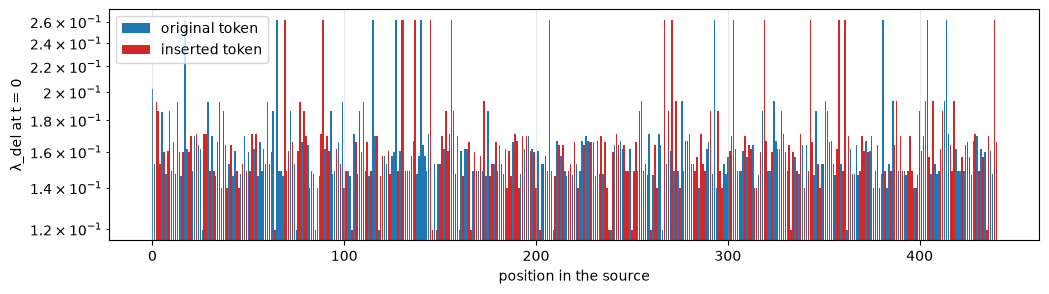

In [14]:
ckpt_path = sorted((RUN / "checkpoints").glob("best-*.ckpt")) or [RUN / "checkpoints" / "last.ckpt"]
checkpoint = torch.load(ckpt_path[-1], map_location="cpu", weights_only=False)
model = load_model(checkpoint, OmegaConf.create(checkpoint["config"]), ema=True).to(device)
print(f"loaded {ckpt_path[-1].name}: {count(model):,} parameters")
print(model.encoder.__class__.__name__, "->", model.head.__class__.__name__)

edit_flow = EditFlow(probability_path=instantiate(cfg.task.path), bos_token=dm.bos_token, low_discrepancy_sampling=cfg.task.low_discrepancy_sampling)

x_0d, x_1d = to_device(x_0, device), to_device(x_1, device)
with torch.inference_mode():
    rate = model(x_0d, torch.zeros(x_0d.batch_size, device=device))
print("log_lambdas", tuple(rate.log_lambdas.shape), " Q_logits", tuple(rate.Q_logits.shape))

# deletion rate per token of the first source at t = 0, insertions marked
n = x_0.seq_lens[0]
lam = rate.log_lambda_del[:n].cpu().exp()
ins = x_0.inserted[:n]
plt.figure(figsize=(12, 3))
plt.bar(np.arange(n)[~ins.numpy()], lam[~ins], color="tab:blue", label="original token")
plt.bar(np.arange(n)[ins.numpy()], lam[ins], color="tab:red", label="inserted token")
plt.yscale("log"); plt.xlabel("position in the source"); plt.ylabel("λ_del at t = 0"); plt.legend(); plt.show()

In [15]:
# Any encoder with the interface plugs in — here a context-free one (it cannot work well, it sees one token at a time)
from torch import nn
from editflows.edit_head import EncoderWithEditHead

class ContextFreeEncoder(nn.Module):
    def __init__(self, vocab_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, hidden_size)
    def forward(self, x_t):
        return self.embedding(x_t.x)

toy = EncoderWithEditHead(encoder=ContextFreeEncoder(dm.vocab_size, 16), vocab_size=dm.vocab_size)
print(toy(x_0, torch.rand(x_0.batch_size)).log_lambdas.shape)

torch.Size([3, 2242])


## 7. The objective

`EditFlow.bregman_divergence` samples $t$ (low-discrepancy over the batch), $z_t$, runs the model on $x_t$ and
returns, per sequence,

$$\underbrace{\sum_i \big(\lambda^{\text{ins}}_i + \lambda^{\text{sub}}_i + \lambda^{\text{del}}_i\big)}_{\text{total rate (penalised)}}
\;-\; \frac{\dot\kappa}{1-\kappa}\sum_{\text{needed edits}} \log u_\theta(\text{that edit}) .$$

With our alignment the second sum runs over the still-present insertions and asks for their *deletion*
rate; insert and substitute rates only ever appear in the penalty, so training drives them towards the
floor $e^{-10}$. The cell compares the trained model with an untrained one and shows how the rate mass is
distributed over the three operations.

In [16]:
def rate_mass(m, x, t):
    with torch.inference_mode():
        r = m(x, t)
    return {k: float(v) for k, v in zip(("ins", "sub", "del"), r.log_lambdas.exp().sum(dim=1))}

gen = torch.Generator(device).manual_seed(0)
z_0d, z_1d = z_0.to(device), z_1.to(device)
untrained = instantiate(OmegaConf.create(checkpoint["config"]).task.model).to(device).eval()
for name, m in (("trained", model), ("untrained", untrained)):
    loss = edit_flow.bregman_divergence(m, z_0=z_0d, z_1=z_1d, generator=gen)
    print(f"{name:9s} loss per sequence: {loss.detach().cpu().numpy().round(1)}   rate mass at t=0.5: {rate_mass(m, x_0d, torch.full((x_0.batch_size,), 0.5, device=device))}")

trained   loss per sequence: [ 327.1  398.1 -123.4  297.3]   rate mass at t=0.5: {'ins': 0.668255627155304, 'sub': 0.9086718559265137, 'del': 1255.394287109375}


untrained loss per sequence: [ 5222.5  3912.8 10902.  12316.1]   rate mass at t=0.5: {'ins': 3159.57861328125, 'sub': 24826.26171875, 'del': 17377.82421875}


### 🧑‍💻 Exercise 4


Compute the loss of the trained model at fixed times $t \in \{0.1, 0.5, 0.9\}$ (hint: `path.sample` with a
constant `t`, `rm_blanks`, then the two terms of the formula from `LogRate` — `log_lambda_del` at the
positions where `z_1` is blank, and `cubic.loss_coefficient(t)`). Which $t$ contributes most to the training
signal, and why does the cubic schedule concentrate the signal late?

In [17]:
# 🧑‍💻 Exercise 4 — your code here

## 8. Run analysis

Every run directory holds the Lightning CSV log (`logs/version_N/metrics.csv`, one file per (re)start) and
our per-epoch table `eval/deletion_metrics.csv` with one row per epoch and bucket plus an `all` row. The
questions of the story: do precision *and* recall of the deletions rise, how do they depend on the lengths,
and is there a double-descent-like phase (validation metrics getting worse before they get better again)?

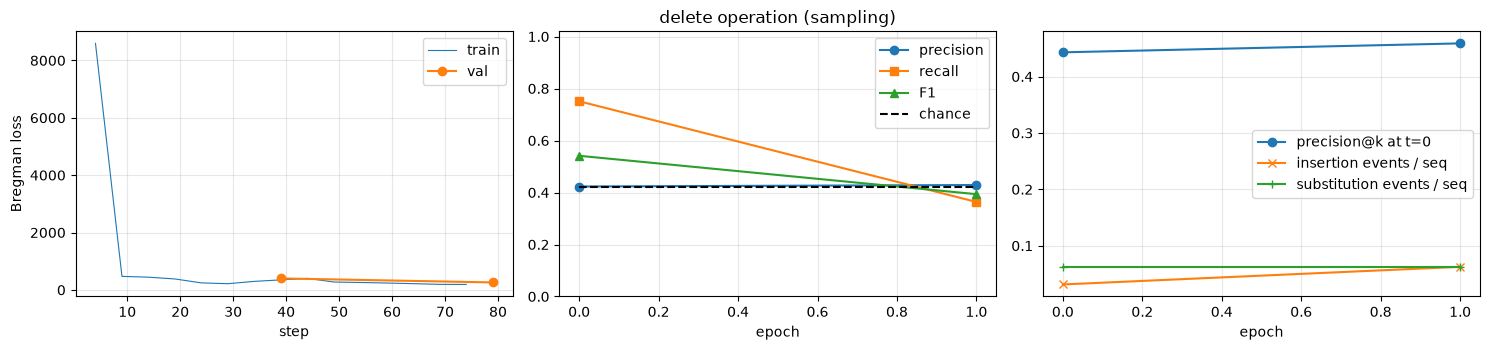

,epoch,step,n_seq,tp,fp,fn,tn,del_precision,del_recall,del_f1,del_chance,rank_p_at_k,exact_match,len_err
12,0,40,32,5820,7935,1930,2738,0.423,0.751,0.541,0.421,0.443,0.0,187.625
25,1,80,32,2819,3755,4931,6918,0.429,0.364,0.394,0.421,0.459,0.0,86.188


In [18]:
logs = pd.concat([pd.read_csv(p) for p in sorted((RUN / "logs").glob("version_*/metrics.csv"))], ignore_index=True)
logs = logs.drop_duplicates("step", keep="last").sort_values("step")
train = logs.dropna(subset=["train/loss"]); val = logs.dropna(subset=["val/loss"])
table = pd.read_csv(RUN / "eval" / "deletion_metrics.csv")
overall = table[(table.stage == "val") & (table.target_len == "all")].sort_values("epoch")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(train.step, train["train/loss"], lw=0.8, label="train"); ax[0].plot(val.step, val["val/loss"], "o-", label="val"); ax[0].set_xlabel("step"); ax[0].set_ylabel("Bregman loss"); ax[0].legend()
ax[1].plot(overall.epoch, overall.del_precision, "o-", label="precision"); ax[1].plot(overall.epoch, overall.del_recall, "s-", label="recall"); ax[1].plot(overall.epoch, overall.del_f1, "^-", label="F1")
ax[1].plot(overall.epoch, overall.del_chance, "k--", label="chance"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.02); ax[1].legend(); ax[1].set_title("delete operation (sampling)")
ax[2].plot(overall.epoch, overall.rank_p_at_k, "o-", label="precision@k at t=0"); ax[2].plot(overall.epoch, overall.ins_per_seq, "x-", label="insertion events / seq"); ax[2].plot(overall.epoch, overall.sub_per_seq, "+-", label="substitution events / seq")
ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.show()
overall[["epoch", "step", "n_seq", "tp", "fp", "fn", "tn", "del_precision", "del_recall", "del_f1", "del_chance", "rank_p_at_k", "exact_match", "len_err"]].round(3)

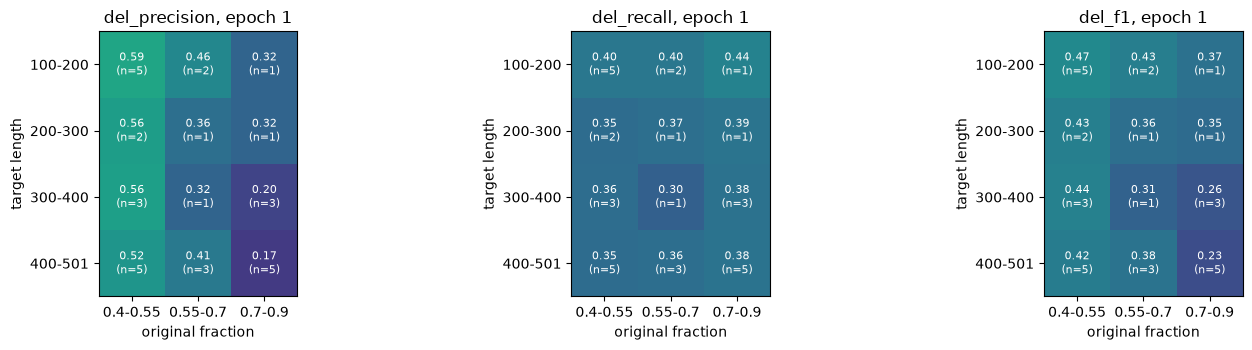

In [19]:
last_epoch = overall.epoch.max()
buckets = table[(table.stage == "val") & (table.epoch == last_epoch) & (table.target_len != "all")]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, metric in zip(ax, ("del_precision", "del_recall", "del_f1")):
    pivot = buckets.pivot(index="target_len", columns="fraction", values=metric)
    counts = buckets.pivot(index="target_len", columns="fraction", values="n_seq")
    im = a.imshow(pivot.values, vmin=0, vmax=1, cmap="viridis"); a.set_xticks(range(pivot.shape[1]), pivot.columns); a.set_yticks(range(pivot.shape[0]), pivot.index)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            if counts.values[i, j] > 0:
                a.text(j, i, f"{pivot.values[i, j]:.2f}\n(n={int(counts.values[i, j])})", ha="center", va="center", color="w", fontsize=8)
    a.set_title(f"{metric}, epoch {last_epoch}"); a.set_xlabel("original fraction"); a.set_ylabel("target length"); a.grid(False)
plt.tight_layout(); plt.show()

### 🧑‍💻 Exercise 5


The `all` rows mix all lengths. Plot `del_f1` per epoch for each target-length bucket separately (one line
per bucket). Do long targets learn later than short ones? If the curves dip and recover, you are looking at
the kind of non-monotone behaviour the story asks about — compare with the training loss at those steps.

In [20]:
# 🧑‍💻 Exercise 5 — your code here

## 9. What did the model learn? Rates per token and the ranking proxy

The sampling metrics of §8 depend on the whole Euler trajectory. A cheaper, threshold-free view: run the
model once on the untouched source at $t = 0$, rank the tokens of each sequence by their deletion rate and
check how many of the top-$k$ ($k$ = number of insertions) are insertions — `rank_p_at_k`. The cells show the
rates of one source at several times and the proxy on a few hundred validation sources.

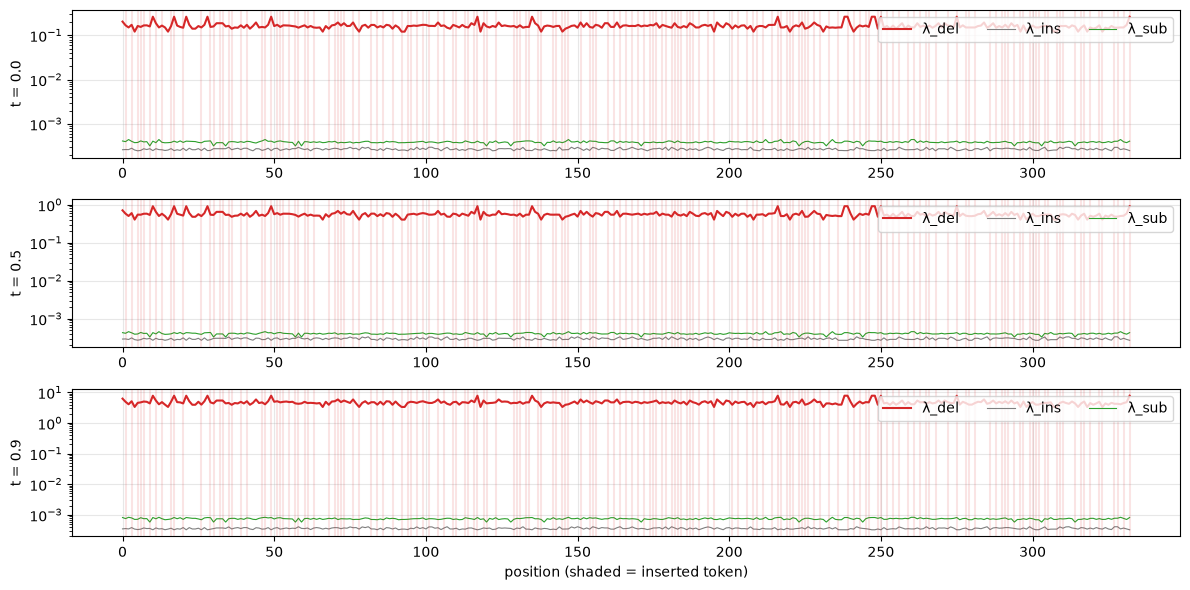

In [21]:
i = 1
n_i = x_0.seq_lens[i]; start = sum(x_0.seq_lens[:i])
ins_i = x_0.inserted[start:start + n_i].numpy()
plt.figure(figsize=(12, 6))
for k, tt in enumerate((0.0, 0.5, 0.9)):
    with torch.inference_mode():
        r = model(x_0d, torch.full((x_0d.batch_size,), tt, device=device))
    lam = r.log_lambdas.exp().cpu()[:, start:start + n_i]
    plt.subplot(3, 1, k + 1)
    plt.plot(lam[2], color="tab:red", label="λ_del"); plt.plot(lam[0], color="tab:gray", lw=0.8, label="λ_ins"); plt.plot(lam[1], color="tab:green", lw=0.8, label="λ_sub")
    for p in np.flatnonzero(ins_i):
        plt.axvline(p, color="tab:red", alpha=0.12)
    plt.yscale("log"); plt.ylabel(f"t = {tt}"); plt.legend(loc="upper right", ncol=3)
plt.xlabel("position (shaded = inserted token)"); plt.tight_layout(); plt.show()

In [22]:
buckets_cfg = Buckets(cfg.task.eval.target_len_bins, cfg.task.eval.fraction_bins)
rank_counts = DeletionCounts(buckets_cfg, device=device)
x_0v, x_1v = to_device(x_0_val, device), to_device(x_1_val, device)
with torch.inference_mode():
    r = model(x_0v, torch.zeros(x_0v.batch_size, device=device))
rank_counts.update_ranking(r.log_lambda_del, x_0v, buckets_cfg.index_pair(x_0v, x_1v))
print(f"precision@k at t = 0 over {x_0v.batch_size} validation sources: {rank_counts.summary()['rank_p_at_k']:.3f}   (chance: {x_0_val.inserted.float().mean():.3f})")

precision@k at t = 0 over 300 validation sources: 0.436   (chance: 0.377)


## 10. Watching the model edit

`EditFlow.sample_flow_euler` returns every intermediate state of the Euler sampler. Because the source
carries `origin` (the index of each token in the source), every intermediate state tells which source tokens
are still there — the inserted letters are shown in lower case as long as they survive. The last cell
computes the full confusion matrix of the delete operation on a few validation sources exactly as
`DeletionTask` and `evaluate.py` do.

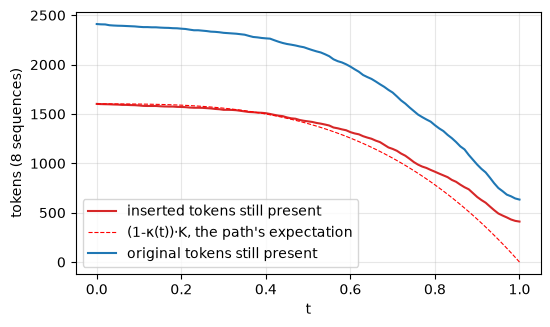

t = 0.00: gfcrPeAShQRlIrGgOCElHKjCJIqHmFKPjGDSfjHsqmkBcCcGLeECkaIBAONstEGAcPJLKQsJqFnGCAjoSoQRbIjNGMpBIGObHkJT
t = 0.50: gfcrPeASQRlIrGgOCElKjCJqHmFKPjDSfjHsqmkBcCGeCkIONstEGcJKQsJFnGAjoSoQRbIjNGMpBIGObHkJaPTnBiODikOQpErQ
t = 0.75: creAQRlIrGClKjCJqHmFKPDSfjsqmkBcCeCIOsEGcQJFnGAjSQRbjNGGObHkaPnOikOQpEQtfRiOKjMPePCbOHDQNEGpAPKSreiS
t = 0.90: reAQRIGlJHFKPSfsqkCeOsEGcQJFnGAjSQbjNGGHkaniOQpEQtfijMePCbOHDQEGAPSreiCHgnDQOJTpQpHLGSSeqRCCrIMMKjlP
t = 1.00: reAQRGJFPfsCsEGQFAjSbjNGGHkOQpEQtfijMePbHDEAPSeiCHgnQTpQpHGSSRCrIMMlDQFoTqEGAQRCoSIGCSKGkDSEFrnk
        (lower case = inserted letter still present, [X] = a letter the model inserted)


In [23]:
n_show = 8
x_1s = DataBatch.from_sequences([dm.val_data[i] for i in range(n_show)])
x_0s, _ = ExtendedCoupling(original_fraction=(0.6, 0.6), n_letters=dm.n_letters, bos_token=dm.bos_token).couple(None, x_1s, generator=torch.Generator().manual_seed(7))
x_0s = to_device(x_0s, device); x_0s.origin = torch.arange(len(x_0s.x), device=device)
states = edit_flow.sample_flow_euler(model, x_0=x_0s, n_steps=100, generator=torch.Generator(device).manual_seed(0))

inserted = x_0s.inserted
remaining_ins = [int(inserted[s.origin[s.origin >= 0]].sum()) for s in states]
remaining_orig = [int((~inserted[s.origin[s.origin >= 0]]).sum()) for s in states]
tt = np.linspace(0, 1, len(states))
plt.figure(figsize=(6, 3.4))
plt.plot(tt, remaining_ins, color="tab:red", label="inserted tokens still present")
plt.plot(tt, (1 - tt ** 3) * remaining_ins[0], "r--", lw=0.8, label="(1-κ(t))·K, the path's expectation")
plt.plot(tt, remaining_orig, color="tab:blue", label="original tokens still present")
plt.xlabel("t"); plt.ylabel("tokens (8 sequences)"); plt.legend(); plt.show()

def snapshot(state, i, width=100):
    lens = list(state.seq_lens)
    toks = torch.split(state.x, lens)[i].cpu(); org = torch.split(state.origin, lens)[i].cpu()
    out = []
    for tkn, o in zip(toks.tolist()[1:], org.tolist()[1:]):
        c = dm.alphabet[tkn] if tkn < dm.n_letters else "^"
        out.append(c.lower() if (o >= 0 and bool(inserted[o])) else (f"[{c}]" if o < 0 else c))
    return "".join(out)[:width]

for step in (0, 50, 75, 90, 100):
    print(f"t = {step / 100:4.2f}: {snapshot(states[step], 0)}")
print("        (lower case = inserted letter still present, [X] = a letter the model inserted)")

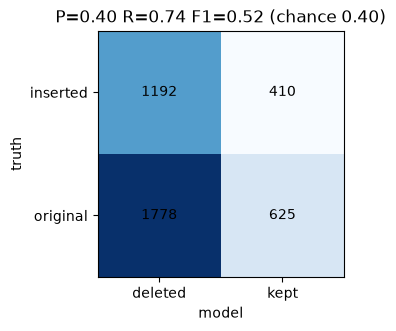

target  : PASQRIGOCEHKCJIHFKPGDSHBCGLECIBAONEGAPJLKQJFGCASQRINGMBIGOHJTPTBODOQEQRSTOKTEMPPCOHJDCCQNEGAPKSCLSCHCDPQOEJRTQGGPNRHRLLGSSJKRCCNIMGMKJPDQQIEMPPFCLSOFPSTOCEEDTKGAQQIRCCMETSKKGAPIARGPJCSKGRDHSOFPINEGFDHISPSEIOMCEEQKGRHCBDS
source  : gfcrPeAShQRlIrGgOCElHKjCJIqHmFKPjGDSfjHsqmkBcCcGLeECkaIBAONstEGAcPJLKQsJqFnGCAjoSoQRbIjNGMpBIGObHkJTaPTnBiODikOQpErnQtfRipSiTOKTEjMpcPePCbOfHJDCCbQNgEtGmapAPKthSrCeaLbidbSCHCgnkDPQOEtJRTpQGGpPNRHgRLLGSSleJKqRbCCtNrIMGMKmjhlJfPDQjQIEiMPPFmhCcLSObfFgPaoStTqOpCgEEkDTKjGjrAQnlQrIRlCoCiMETSmnfoKnKGrAPhIARGPhoJmCSfKoGRkgDHSaOotFPINEGiqFDHISPdSEIOreMCEEQnaoKhgkGRqhHCBDrSd
verdict : +++_x_.x+..+x+.+xxx+xx+x.x+x+.x.+xxx_+x_+++x+.+xx+xx++xxxxx_+..x+xxxx.+x+.+xx._+.+xx_x_..x+xx.x+._xx+xx+x+xx++.._.++.__x++x_xxxxx_.++x_.x_x+.x.xx+xx+.+x+++..x++.+x_+x+_++x..x__+xx.xx+xx._.xx_xxx.+xxx...++xx+.+.x+x_..x.x+++_x+x..+xxx+xxx.++x+xxx++x+x+_x+._x+x+x.+xxx+.++..++x+x.+._x+xxx.++++x+xx+xx+.xx.x++x+..+.+.x_+.x.+x++xxxx.x++.xxxxx+xxxx_+xxxxx_++x++_xx++xxxx+x+   (+ correct 

In [24]:
# The confusion matrix of the delete operation on these sources (same code path as the per-epoch evaluation)
counts = DeletionCounts(buckets_cfg, device=device)
counts.update_sampling(x_0s, to_device(x_1s, device), states[-1], buckets_cfg.index_pair(x_0s, to_device(x_1s, device)))
s = counts.summary()
tp, fp, fn, tn = (int(counts.counts[:, j].sum()) for j in (1, 2, 3, 4))   # columns tp, fp, fn, tn of COUNTS
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow([[tp, fn], [fp, tn]], cmap="Blues"); ax.set_xticks([0, 1], ["deleted", "kept"]); ax.set_yticks([0, 1], ["inserted", "original"]); ax.grid(False)
for (i, j), v in np.ndenumerate([[tp, fn], [fp, tn]]):
    ax.text(j, i, f"{v}", ha="center", va="center", color="k")
ax.set_xlabel("model"); ax.set_ylabel("truth"); ax.set_title(f"P={s['del_precision']:.2f} R={s['del_recall']:.2f} F1={s['del_f1']:.2f} (chance {s['del_chance']:.2f})")
plt.show()
print(render(dm, x_0s, to_device(x_1s, device), states[-1], 0))

### 🧑‍💻 Exercise 6


Sample with fewer Euler steps (`n_steps=10`) and with more (`n_steps=400`) and compare precision and
recall. Then start the sampler *late*: build `x_t` at $t = 0.5$ from the known $z_0, z_1$ (§5) and run only
the second half of the schedule — does the model still remove the remaining insertions?

In [25]:
# 🧑‍💻 Exercise 6 — your code here

## 11. Summary

* **Data:** known targets over 20 letters from a file; the placeholder is a Markov chain because structure
  is what makes insertions detectable.
* **Coupling and alignment:** the source is the target with $K$ uniform letters inserted; the alignment is
  known and consists of deletions only, so the flow has to learn exactly one thing.
* **Model:** a time-blind sequence encoder behind a fixed interface plus the edit-flow head; the real
  encoder is a config change.
* **Training:** upstream's Edit Flows loss, unchanged, in a Lightning loop configured with Hydra, epoch
  based, with per-epoch deletion metrics in `eval/deletion_metrics.csv` and checkpoints that resume.
* **Evaluation:** the confusion matrix of the delete operation (precision, recall, F1 vs chance) by target
  length and original fraction, plus a ranking proxy at $t = 0$ and the counts of spurious insertions and
  substitutions. `evaluate.py` does the same for any checkpoint.

Next steps in the project: the real target sequences, the real sequence encoder, and the GPU runs of
`experiment=deletion-base` (`docs/CLUSTER.md`).